In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
ds = xr.load_dataset("ERA5_features/grib_files/soil_moist_layer1.grib", engine="cfgrib")
var_daily1 = ds.swvl1.groupby(ds.swvl1.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/soil_moist_layer1.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
ds = xr.load_dataset("ERA5_features/grib_files/soil_moist_layer2.grib", engine="cfgrib")
var_daily2 = ds.swvl2.groupby(ds.swvl2.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/soil_moist_layer2.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
var_daily = 7*var_daily1 + 21*var_daily2
var_daily = var_daily.reset_coords(['number', 'step'], drop=True)

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))

In [8]:
ds_oro = xr.load_dataset("ERA5_features/grib_files/orography_1deg_res.grib", engine="cfgrib")
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

Ignoring index file 'ERA5_features/grib_files/orography_1deg_res.grib.5b7b6.idx' incompatible with GRIB file


In [9]:
g = 9.80665
lat = ds_oro.latitude
land_frac = ds_oro.lsm
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)
land_filt = xr.where(land_frac > 0.5, 1, 0)

In [10]:
weights = np.cos(np.deg2rad(lat))*mount_filt*land_filt
weights.name = "weights"

In [11]:
lon_min = 4
lon_max = 42
lat_max = 72
lat_min = 59

var_daily_regmean = var_daily.sel(longitude=slice(lon_min,lon_max), latitude=slice(lat_max,lat_min)).weighted(weights).mean(dim=['longitude', 'latitude'])

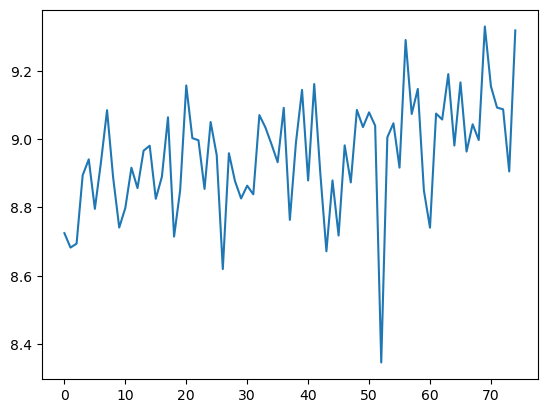

In [12]:
var_seasonmean_regmean = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")).mean(dim='date')
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)

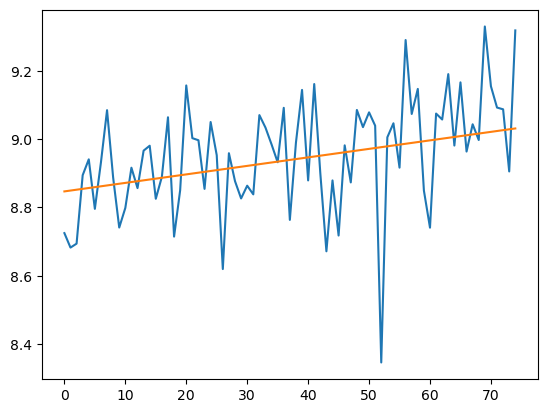

In [13]:
fit_par = np.polyfit(var_seasonmean_regmean[:60].year, var_seasonmean_regmean[:60], 1)
var_seasonmean_regmean_gws = np.polyval(fit_par, var_seasonmean_regmean.year)

plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean_gws)

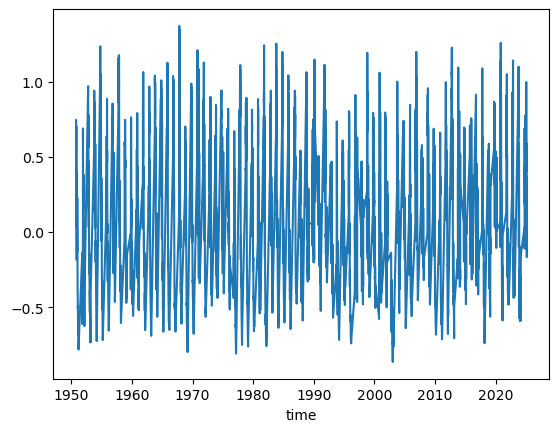

In [14]:
var_daily_regmean_detr = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")) - var_seasonmean_regmean_gws[:, np.newaxis]
var_daily_regmean_detr = var_daily_regmean_detr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)
var_daily_regmean_detr.plot()

In [15]:
var_7dMean_regmean_detr = var_daily_regmean_detr.rolling(time=7, min_periods=7, center=True).mean() 
month = var_7dMean_regmean_detr.time.dt.month
day = var_7dMean_regmean_detr.time.dt.day
var_7dMean_regmean_detr = var_7dMean_regmean_detr.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

var_7dMean_regmean_detr_train = var_7dMean_regmean_detr.sel(time=slice("1950-07", "2010-06"))

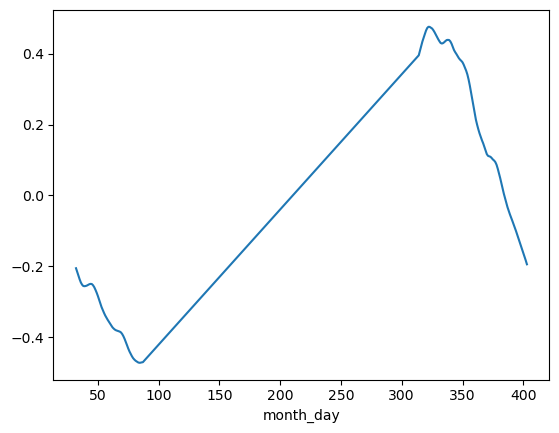

In [16]:
var_7dMean_regmean_detr_anom = var_7dMean_regmean_detr.groupby('month_day') - var_7dMean_regmean_detr_train.groupby('month_day').mean()
var_7dMean_regmean_detr_train.groupby('month_day').mean().plot()

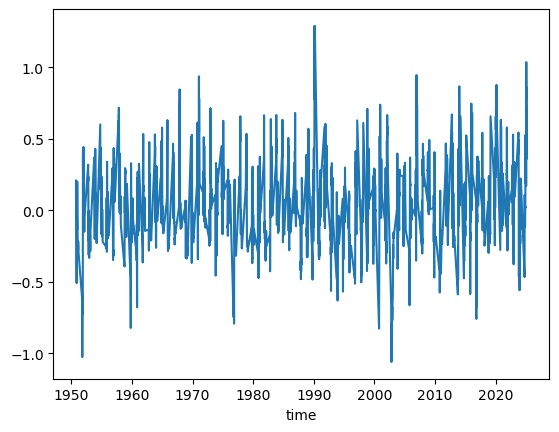

In [17]:
var_7dMean_regmean_detr_anom.plot()

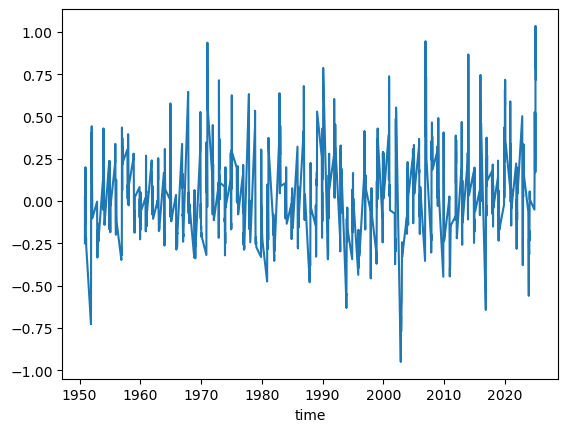

In [18]:
month = var_7dMean_regmean_detr_anom.time.dt.month
day = var_7dMean_regmean_detr_anom.time.dt.day
var_7dMean_regmean_detr_anom_week3 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_regmean_detr_anom_week4 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28)))
var_7dMean_regmean_detr_anom_week5 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 30)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 21)))
var_7dMean_regmean_detr_anom_week6 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 23)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 14)))
var_7dMean_regmean_detr_anom_week7 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 16)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 7)))
var_7dMean_regmean_detr_anom_week3.plot()

In [19]:
df_var_week3 = var_7dMean_regmean_detr_anom_week3.to_dataframe(name='soil_moist_upper')
df_var_week3 = df_var_week3.drop(['month_day'], axis=1)
df_var_week3

,soil_moist_upper
time,
1950-11-13,-0.249448
1950-11-14,-0.152320
1950-11-15,-0.072944
1950-11-16,-0.015719
1950-11-17,0.022580
...,...
2025-01-31,0.846842
2025-02-01,0.827596
2025-02-02,0.805465


In [20]:
df_var_week3.to_csv('sm_upper_NE_week3_scaled.csv')

In [3]:
df_unscaled = pd.read_csv('sm_upper_NE_week3_detr.csv')
df_unscaled4 = pd.read_csv('sm_upper_NE_week4_detr.csv')
df_unscaled5 = pd.read_csv('sm_upper_NE_week5_detr.csv')

In [10]:
print(np.corrcoef(df_unscaled['soil_moist_upper'],df_unscaled4['soil_moist_upper'])[0,1])
print(np.corrcoef(df_unscaled['soil_moist_upper'],df_unscaled5['soil_moist_upper'])[0,1])

0.7789905933114809
0.5551496308810412


In [24]:
np.corrcoef(df_unscaled['soil_moist_upper'],df_var_week3['soil_moist_upper'])[0,1]

np.float64(0.9951438355429023)

In [16]:
df_nao3 = pd.read_csv('NAO_week3.csv')
df_nao4 = pd.read_csv('NAO_week4.csv')
df_nao5 = pd.read_csv('NAO_week5.csv')
df_nao6 = pd.read_csv('NAO_week6.csv')

In [17]:
print(np.corrcoef(df_nao4['nao_index'],df_nao3['nao_index'])[0,1])
print(np.corrcoef(df_nao5['nao_index'],df_nao3['nao_index'])[0,1])
print(np.corrcoef(df_nao6['nao_index'],df_nao3['nao_index'])[0,1])

0.530605709616354
0.2139271253493814
0.18380278285232027


In [4]:
print(np.corrcoef(df_unscaled['soil_moist_upper'],df_nao3['nao_index'])[0,1])
print(np.corrcoef(df_unscaled['soil_moist_upper'],df_nao4['nao_index'])[0,1])
print(np.corrcoef(df_unscaled['soil_moist_upper'],df_nao5['nao_index'])[0,1])

0.2765133152107076
0.2865881927688522
0.2083998507985004


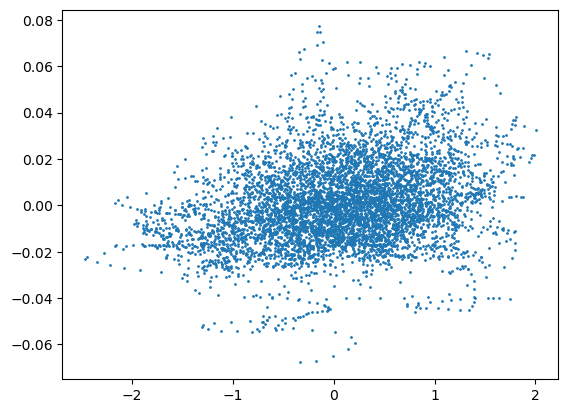

In [5]:
plt.plot(df_nao3['nao_index'], df_unscaled['soil_moist_upper'],'o', markersize=1)

In [4]:
df_temp_NE = pd.read_csv('target_temp_NE_quadr_moanom.csv')
df_precip_NE = pd.read_csv('target_precip_NE_lin_moanom.csv')

In [7]:
print(np.corrcoef(df_temp_NE['t2m'],df_nao3['nao_index'])[0,1])
print(np.corrcoef(df_temp_NE['t2m'],df_nao4['nao_index'])[0,1])
print(np.corrcoef(df_temp_NE['t2m'],df_nao5['nao_index'])[0,1])

0.13297659978341228
0.13281891424640874
0.12300214766233769


In [6]:
print(np.corrcoef(df_temp_NE['t2m'],df_unscaled['soil_moist_upper'])[0,1])
print(np.corrcoef(df_temp_NE['t2m'],df_unscaled4['soil_moist_upper'])[0,1])
print(np.corrcoef(df_temp_NE['t2m'],df_unscaled5['soil_moist_upper'])[0,1])

0.17728712013512243
0.12170310256159703
0.07642741707584294


In [9]:
print(np.corrcoef(df_precip_NE['tp'],df_nao3['nao_index'])[0,1])
print(np.corrcoef(df_precip_NE['tp'],df_nao4['nao_index'])[0,1])
print(np.corrcoef(df_precip_NE['tp'],df_nao5['nao_index'])[0,1])

0.12241808696802751
0.09623633795193104
0.07658187003026534


In [8]:
print(np.corrcoef(df_precip_NE['tp'],df_unscaled['soil_moist_upper'])[0,1])
print(np.corrcoef(df_precip_NE['tp'],df_unscaled4['soil_moist_upper'])[0,1])
print(np.corrcoef(df_precip_NE['tp'],df_unscaled5['soil_moist_upper'])[0,1])

0.13898107335935722
0.08935511119264372
0.0728296863097837


In [11]:
print(np.corrcoef(df_precip_NE['tp'],df_temp_NE['t2m'])[0,1])

0.5242195941074455


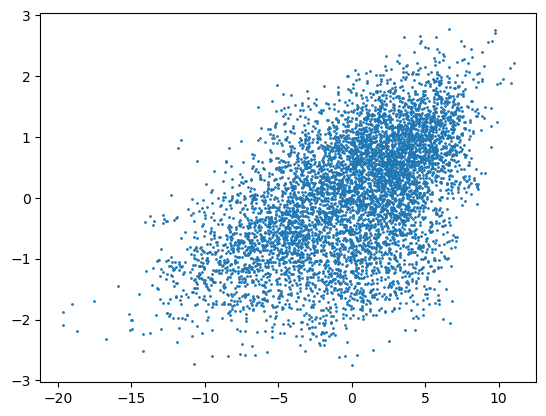

In [13]:
plt.plot(df_temp_NE['t2m'], df_precip_NE['tp'],'o', markersize=1)